# Lecture Notes: The Chain Rule
*Stewart, **Calculus**, 9th ed., §3.4*

**Learning objectives.** By the end of this lecture you should be able to:
1. Recognize a **composite function** $F = f\circ g$ and identify its outer function $f$ and inner function $g$.
2. State the **Chain Rule** in both prime and Leibniz notation, and interpret it as multiplying rates of change.
3. Use the **Power Rule combined with the Chain Rule** to differentiate $[g(x)]^n$.
4. Differentiate $b^x$ for any base $b > 0$.
5. Apply the Chain Rule several times to longer chains, and together with the Product and Quotient Rules.
6. Check every answer symbolically with **SymPy** and numerically with **NumPy**.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import Math, display

sp.init_printing()
x, t, u, theta = sp.symbols("x t u theta")

## 1. Where we are

From §3.1–3.3 we can differentiate:

| Function | Derivative |
|---|---|
| $x^n$ | $n x^{n-1}$ |
| $e^x$ | $e^x$ |
| $\sin x,\ \cos x,\ \tan x$ | $\cos x,\ -\sin x,\ \sec^2 x$ |
| $f\,g$ | $f g' + g f'$ |
| $\dfrac{f}{g}$ | $\dfrac{g f' - f g'}{g^2}$ |

None of these rules can handle
$$F(x) = \sqrt{x^2 + 1}.$$
$F$ is a **composite function**: if $y = f(u) = \sqrt u$ and $u = g(x) = x^2 + 1$, then $y = F(x) = f(g(x))$, so $F = f\circ g$. We call $f$ the **outer** function and $g$ the **inner** function. We already know how to differentiate $f$ and $g$. The Chain Rule tells us how to put those derivatives together.

As before, the helper below compares a derivative found by hand with SymPy's answer.

In [2]:
def check(f, by_hand, var=x):
    """Display d/dvar f = by_hand and confirm it agrees with SymPy."""
    ok = sp.simplify(sp.diff(f, var) - by_hand) == 0
    display(Math(rf"\frac{{d}}{{d{sp.latex(var)}}}\left({sp.latex(f)}\right) = {sp.latex(by_hand)}"))
    print("Agrees with SymPy:", ok)

## 2. The Chain Rule

**Motivation: rates multiply.** Suppose $u$ changes twice as fast as $x$, and $y$ changes three times as fast as $u$. Then $y$ changes $3 \cdot 2 = 6$ times as fast as $x$:
$$\frac{du}{dx} = 2,\quad \frac{dy}{du} = 3 \quad\Longrightarrow\quad \frac{dy}{dx} = \frac{dy}{du}\cdot\frac{du}{dx} = 6.$$
Think of three gears: if gear $A$ turns $x$ times, gear $B$ turns $u$ times, and gear $C$ turns $y$ times, the gear ratios multiply.

**The Chain Rule.** If $g$ is differentiable at $x$ and $f$ is differentiable at $g(x)$, then $F = f\circ g$ is differentiable at $x$ and
$$\boxed{F'(x) = f'\big(g(x)\big)\cdot g'(x)}$$
In Leibniz notation, if $y = f(u)$ and $u = g(x)$ are both differentiable, then
$$\boxed{\frac{dy}{dx} = \frac{dy}{du}\,\frac{du}{dx}}$$
In words: *the derivative of the outer function, evaluated at the inner function, times the derivative of the inner function.*

**Warning:** in $f'(g(x))$ the inner function is left **unchanged** inside $f'$. Differentiate the outside first, keep the inside as it is, then multiply by the derivative of the inside.

**Leibniz notation is a good memory aid, but $du$ does not really "cancel."** $\dfrac{dy}{du}$ is not a fraction. The rule still has to be proved (see §7).

We check the rule for general functions $f$ and $g$:

In [3]:
f, g = sp.Function("f"), sp.Function("g")
lhs = sp.diff(f(g(x)), x)
rhs = f(u).diff(u).subs(u, g(x)) * sp.diff(g(x), x)
display(Math(rf"\frac{{d}}{{dx}}f(g(x)) = {sp.latex(lhs)}"))
print("Chain rule holds:", sp.simplify(lhs - rhs) == 0)

<IPython.core.display.Math object>

Chain rule holds: True


**Example 1.** Find $F'(x)$ if $F(x) = \sqrt{x^2 + 1}$.

*By hand.* The outer function is $f(u) = \sqrt u = u^{1/2}$, so $f'(u) = \dfrac{1}{2\sqrt u}$. The inner function is $g(x) = x^2 + 1$, so $g'(x) = 2x$.
$$F'(x) = f'\big(g(x)\big)\cdot g'(x) = \frac{1}{2\sqrt{x^2+1}}\cdot 2x = \frac{x}{\sqrt{x^2+1}}.$$

*In Leibniz notation.* Let $u = x^2 + 1$ and $y = \sqrt u$. Then
$$\frac{dy}{dx} = \frac{dy}{du}\,\frac{du}{dx} = \frac{1}{2\sqrt u}\cdot 2x = \frac{x}{\sqrt{x^2+1}}.$$

In [4]:
check(sp.sqrt(x**2 + 1), x / sp.sqrt(x**2 + 1))

<IPython.core.display.Math object>

Agrees with SymPy: True


**Example 2.** Differentiate (a) $y = \sin(x^2)$ and (b) $y = \sin^2 x$.

These look alike but are different compositions.

*(a)* The outer function is $\sin$, the inner function is $x^2$:
$$\frac{dy}{dx} = \underbrace{\cos(x^2)}_{\text{outer}'\text{ at inner}}\cdot\underbrace{2x}_{\text{inner}'} = 2x\cos(x^2).$$

*(b)* $\sin^2 x$ means $(\sin x)^2$. The outer function is squaring, the inner function is $\sin$:
$$\frac{dy}{dx} = 2(\sin x)\cdot\cos x = 2\sin x\cos x = \sin 2x.$$

In [5]:
check(sp.sin(x**2), 2*x * sp.cos(x**2))
check(sp.sin(x)**2, sp.sin(2*x))

<IPython.core.display.Math object>

Agrees with SymPy: True


<IPython.core.display.Math object>

Agrees with SymPy: True


The plot shows why the factor $2x$ appears in (a). As $|x|$ grows, $x^2$ grows faster and faster, so $\sin(x^2)$ oscillates faster and faster. Its slopes get steeper, and the derivative $2x\cos(x^2)$ has a growing envelope $\pm 2x$.

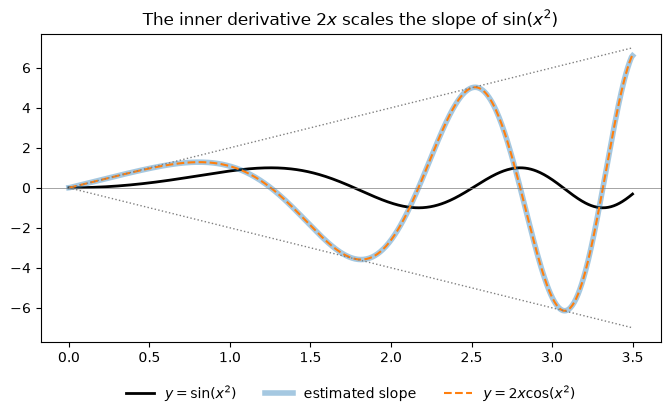

In [6]:
xs = np.linspace(0, 3.5, 600)
slopes = np.gradient(np.sin(xs**2), xs)  # numerical estimate of the slope

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(xs, np.sin(xs**2), "k", lw=2, label=r"$y = \sin(x^2)$")
ax.plot(xs, slopes, lw=4, alpha=0.4, label=r"estimated slope")
ax.plot(xs, 2 * xs * np.cos(xs**2), "--", lw=1.5, label=r"$y = 2x\cos(x^2)$")
ax.plot(xs, 2 * xs, ":", color="gray", lw=1)
ax.plot(xs, -2 * xs, ":", color="gray", lw=1)
ax.axhline(0, color="gray", lw=0.5)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
ax.set_title(r"The inner derivative $2x$ scales the slope of $\sin(x^2)$")
plt.show()

## 3. The Power Rule combined with the Chain Rule

When the outer function is a power, $y = u^n$ with $u = g(x)$, the Chain Rule gives:
$$\boxed{\frac{d}{dx}\big[g(x)\big]^n = n\big[g(x)\big]^{n-1}\,g'(x)}
\qquad\text{or}\qquad
\frac{d}{dx}\left(u^n\right) = n u^{n-1}\,\frac{du}{dx}.$$
The ordinary Power Rule is the case $g(x) = x$, where $g'(x) = 1$.

**Example 3.** Differentiate $y = (x^3 - 1)^{100}$.

*By hand.* Do **not** expand this. With $u = x^3 - 1$:
$$\frac{dy}{dx} = 100(x^3 - 1)^{99}\cdot 3x^2 = 300x^2(x^3-1)^{99}.$$

In [7]:
check((x**3 - 1)**100, 300 * x**2 * (x**3 - 1)**99)

<IPython.core.display.Math object>

Agrees with SymPy: True


**Example 4.** Find $f'(x)$ if $f(x) = \dfrac{1}{\sqrt[3]{x^2 + x + 1}}$.

*By hand.* Rewrite as a power first: $f(x) = (x^2 + x + 1)^{-1/3}$. Then
$$f'(x) = -\frac13 (x^2 + x + 1)^{-4/3}\,(2x + 1) = -\frac{2x+1}{3(x^2+x+1)^{4/3}}.$$
Rewriting as a power avoids the Quotient Rule.

In [8]:
check(1 / sp.cbrt(x**2 + x + 1), -(2*x + 1) / (3 * (x**2 + x + 1)**sp.Rational(4, 3)))

<IPython.core.display.Math object>

Agrees with SymPy: True


**Example 5.** Find the derivative of $g(t) = \left(\dfrac{t - 2}{2t + 1}\right)^9$.

*By hand.* Power Rule + Chain Rule on the outside, Quotient Rule on the inside:
$$g'(t) = 9\left(\frac{t-2}{2t+1}\right)^8 \cdot \frac{(2t+1)\cdot 1 - (t-2)\cdot 2}{(2t+1)^2}
= 9\left(\frac{t-2}{2t+1}\right)^8 \cdot \frac{5}{(2t+1)^2}
= \frac{45(t-2)^8}{(2t+1)^{10}}.$$

In [9]:
check(((t - 2) / (2*t + 1))**9, 45 * (t - 2)**8 / (2*t + 1)**10, var=t)

<IPython.core.display.Math object>

Agrees with SymPy: True


**Example 6.** Differentiate $y = (2x + 1)^5 (x^3 - x + 1)^4$.

*By hand.* The Product Rule on the outside, the Chain Rule for each factor:
$$\begin{aligned}
y' &= (2x+1)^5 \cdot 4(x^3 - x + 1)^3(3x^2 - 1) + (x^3 - x + 1)^4\cdot 5(2x+1)^4\cdot 2 \\
&= 2(2x+1)^4(x^3-x+1)^3\big[\,2(2x+1)(3x^2-1) + 5(x^3-x+1)\,\big] \\
&= 2(2x+1)^4(x^3-x+1)^3\,(17x^3 + 6x^2 - 9x + 3).
\end{aligned}$$
Factoring out the common powers $(2x+1)^4(x^3-x+1)^3$ keeps the answer readable.

In [10]:
check((2*x + 1)**5 * (x**3 - x + 1)**4,
      2 * (2*x + 1)**4 * (x**3 - x + 1)**3 * (17*x**3 + 6*x**2 - 9*x + 3))

<IPython.core.display.Math object>

Agrees with SymPy: True


## 4. Exponential functions

**Example 7.** Differentiate $y = e^{\sin x}$.

*By hand.* The outer function is $e^u$ (its own derivative), the inner function is $u = \sin x$:
$$\frac{dy}{dx} = e^{\sin x}\cdot\cos x.$$
In general, $\dfrac{d}{dx}\,e^{g(x)} = e^{g(x)}\,g'(x)$.

In [11]:
check(sp.exp(sp.sin(x)), sp.exp(sp.sin(x)) * sp.cos(x))

<IPython.core.display.Math object>

Agrees with SymPy: True


**Derivative of $b^x$.** For any base $b > 0$, write $b = e^{\ln b}$, so $b^x = \left(e^{\ln b}\right)^x = e^{(\ln b)x}$. The Chain Rule with inner function $(\ln b)\,x$ gives
$$\frac{d}{dx}\left(b^x\right) = e^{(\ln b)x}\cdot\ln b = b^x \ln b.$$
$$\boxed{\frac{d}{dx}\left(b^x\right) = b^x \ln b}$$
When $b = e$, $\ln e = 1$ and we recover $\dfrac{d}{dx}e^x = e^x$. This is why $e$ is the "natural" base: it is the only base with no extra constant.

**Example 8.** $\dfrac{d}{dx}\left(2^x\right) = 2^x\ln 2 \approx (0.693)\,2^x$. Compare §3.1, where we estimated $\lim_{h\to0}\dfrac{2^h - 1}{h} \approx 0.69$.

In [12]:
b = sp.symbols("b", positive=True)
check(b**x, b**x * sp.log(b))
check(2**x, 2**x * sp.log(2))
print("ln 2 ≈", float(sp.log(2)))

<IPython.core.display.Math object>

Agrees with SymPy: True


<IPython.core.display.Math object>

Agrees with SymPy: True
ln 2 ≈ 0.6931471805599453


## 5. Longer chains

The Chain Rule extends to compositions of three or more functions. If $y = f(u)$, $u = g(v)$, $v = h(x)$, then
$$\frac{dy}{dx} = \frac{dy}{du}\,\frac{du}{dv}\,\frac{dv}{dx},
\qquad\text{i.e.}\qquad
\frac{d}{dx} f\Big(g\big(h(x)\big)\Big) = f'\Big(g\big(h(x)\big)\Big)\cdot g'\big(h(x)\big)\cdot h'(x).$$
Work from the **outside in**, one layer at a time.

**Example 9.** If $f(x) = \sin(\cos(\tan x))$, then
$$\begin{aligned}
f'(x) &= \cos(\cos(\tan x))\cdot\frac{d}{dx}\cos(\tan x) \\
&= \cos(\cos(\tan x))\cdot\big[-\sin(\tan x)\big]\cdot\frac{d}{dx}\tan x \\
&= -\cos(\cos(\tan x))\,\sin(\tan x)\,\sec^2 x.
\end{aligned}$$

In [13]:
check(sp.sin(sp.cos(sp.tan(x))),
      -sp.cos(sp.cos(sp.tan(x))) * sp.sin(sp.tan(x)) * sp.sec(x)**2)

<IPython.core.display.Math object>

Agrees with SymPy: True


**Example 10.** Differentiate $y = e^{\sec 3\theta}$.

*By hand.* Three layers: $e^{(\cdot)}$, then $\sec(\cdot)$, then $3\theta$.
$$\frac{dy}{d\theta} = e^{\sec 3\theta}\cdot\frac{d}{d\theta}(\sec 3\theta)
= e^{\sec 3\theta}\cdot\sec 3\theta\tan 3\theta\cdot\frac{d}{d\theta}(3\theta)
= 3\,e^{\sec 3\theta}\sec 3\theta\tan 3\theta.$$

In [14]:
check(sp.exp(sp.sec(3*theta)),
      3 * sp.exp(sp.sec(3*theta)) * sp.sec(3*theta) * sp.tan(3*theta), var=theta)

<IPython.core.display.Math object>

Agrees with SymPy: True


**Example 11 (values from a table).** Suppose $h(x) = f(g(x))$ with $g(1) = 4$, $g'(1) = 3$, and $f'(4) = 5$. Then
$$h'(1) = f'\big(g(1)\big)\cdot g'(1) = f'(4)\cdot 3 = 15.$$
Note that we need $f'$ at $g(1) = 4$, **not** at $1$.

In [15]:
# h'(1) depends only on g(1), g'(1) and f'(4), so any f and g with those values work,
# e.g. the lines g(x) = 4 + 3(x - 1) and f(u) = 5u.
g_line = 4 + 3 * (x - 1)
f_line = lambda w: 5 * w
print("h'(1) =", sp.diff(f_line(g_line), x).subs(x, 1))

h'(1) = 15


## 6. A numerical sanity check

As in earlier sections, we compare each by-hand derivative with a **central difference** $\dfrac{f(x+h) - f(x-h)}{2h}$ at many points.

In [16]:
def numeric_check(f, fprime, a=0.2, b=1.2, step=1e-6):
    fn, dfn = sp.lambdify(x, f, "numpy"), sp.lambdify(x, fprime, "numpy")
    xs = np.linspace(a, b, 200)
    approx = (fn(xs + step) - fn(xs - step)) / (2 * step)
    exact = dfn(xs)
    return np.max(np.abs(approx - exact)) / np.max(np.abs(exact))

tests = {
    r"\sqrt{x^2+1}": (sp.sqrt(x**2 + 1), x / sp.sqrt(x**2 + 1)),
    r"\sin(x^2)": (sp.sin(x**2), 2*x * sp.cos(x**2)),
    r"(x^3-1)^{100}": ((x**3 - 1)**100, 300 * x**2 * (x**3 - 1)**99),
    r"(2x+1)^5(x^3-x+1)^4": ((2*x + 1)**5 * (x**3 - x + 1)**4,
                             2 * (2*x + 1)**4 * (x**3 - x + 1)**3 * (17*x**3 + 6*x**2 - 9*x + 3)),
    r"e^{\sin x}": (sp.exp(sp.sin(x)), sp.exp(sp.sin(x)) * sp.cos(x)),
    r"2^x": (2**x, 2**x * sp.log(2)),
    r"\sin(\cos(\tan x))": (sp.sin(sp.cos(sp.tan(x))),
                            -sp.cos(sp.cos(sp.tan(x))) * sp.sin(sp.tan(x)) * sp.sec(x)**2),
}
for name, (f, fp) in tests.items():
    rel = numeric_check(f, fp)
    display(Math(rf"{name}: \quad \text{{relative error}} \approx {rel:.1e}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## 7. Why the Chain Rule is true

**A first attempt.** Let $\Delta u = g(x + \Delta x) - g(x)$ and $\Delta y = f(u + \Delta u) - f(u)$. It is tempting to write
$$\frac{\Delta y}{\Delta x} = \frac{\Delta y}{\Delta u}\cdot\frac{\Delta u}{\Delta x}$$
and let $\Delta x \to 0$. Since $g$ is continuous, $\Delta u \to 0$, so the two factors go to $f'(u)$ and $g'(x)$. **The problem:** $\Delta u$ may equal $0$ for $\Delta x \neq 0$ (for example, when $g$ is constant near $x$), and then we divided by zero.

**A correct proof.** Since $g$ is differentiable at $a$, we can write
$$\Delta u = g'(a)\,\Delta x + \varepsilon_1\,\Delta x, \qquad \text{where } \varepsilon_1 \to 0 \text{ as } \Delta x \to 0.$$
Similarly, with $b = g(a)$, since $f$ is differentiable at $b$,
$$\Delta y = f'(b)\,\Delta u + \varepsilon_2\,\Delta u, \qquad \text{where } \varepsilon_2 \to 0 \text{ as } \Delta u \to 0$$
(define $\varepsilon_2 = 0$ when $\Delta u = 0$, so this holds even then). Substituting the first equation into the second,
$$\Delta y = \big[f'(b) + \varepsilon_2\big]\big[g'(a) + \varepsilon_1\big]\Delta x
\quad\Longrightarrow\quad
\frac{\Delta y}{\Delta x} = \big[f'(b) + \varepsilon_2\big]\big[g'(a) + \varepsilon_1\big].$$
No division by $\Delta u$ is needed. As $\Delta x \to 0$, $\Delta u \to 0$, so $\varepsilon_1 \to 0$ and $\varepsilon_2 \to 0$. Therefore
$$\frac{dy}{dx} = \lim_{\Delta x\to0}\frac{\Delta y}{\Delta x} = f'(b)\,g'(a) = f'\big(g(a)\big)\,g'(a). \qquad\blacksquare$$

## 8. Practice problems

Try these by hand first, then run the cell below to check.

1. $y = (5x^4 - 3x)^{7}$
2. $f(x) = \sqrt{1 - 2x}$
3. $y = \cos(a^3 + x^3)$, where $a$ is a constant
4. $y = x e^{-x^2}$
5. $g(t) = \tan^2(3t)$
6. $y = 10^{\,1 - x^2}$
7. $y = \sin\!\big(\sin(\sin x)\big)$
8. Find the tangent line to $y = (1 + 2x)^{10}$ at $(0, 1)$.
9. If $F(x) = f(g(x))$, where $f(-2) = 8$, $f'(-2) = 4$, $f'(5) = 3$, $g(5) = -2$, and $g'(5) = 6$, find $F'(5)$.

In [17]:
a = sp.symbols("a")
problems = [
    ((5*x**4 - 3*x)**7, x),
    (sp.sqrt(1 - 2*x), x),
    (sp.cos(a**3 + x**3), x),
    (x * sp.exp(-x**2), x),
    (sp.tan(3*t)**2, t),
    (10**(1 - x**2), x),
    (sp.sin(sp.sin(sp.sin(x))), x),
]
for i, (f, var) in enumerate(problems, 1):
    df = sp.diff(f, var)
    df = sp.factor(df) if i in (1, 4) else df
    display(Math(rf"\text{{{i}.}}\quad \frac{{d}}{{d{sp.latex(var)}}}\left({sp.latex(f)}\right) = {sp.latex(df)}"))

# 8. tangent line
y = (1 + 2*x)**10
m = sp.diff(y, x).subs(x, 0)
display(Math(rf"\text{{8.}}\quad y = {sp.latex(sp.expand(1 + m*x))}"))

# 9. F'(5) = f'(g(5)) g'(5) = f'(-2) g'(5)
display(Math(rf"\text{{9.}}\quad F'(5) = f'(-2)\cdot g'(5) = {4 * 6}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## Summary

| Function | Derivative | Rule |
|---|---|---|
| $f\big(g(x)\big)$ | $f'\big(g(x)\big)\,g'(x)$ | Chain |
| $\big[g(x)\big]^n$ | $n\big[g(x)\big]^{n-1}g'(x)$ | Power + Chain |
| $e^{g(x)}$ | $e^{g(x)}\,g'(x)$ | Chain |
| $b^x$ | $b^x \ln b$ | Chain ($b^x = e^{x\ln b}$) |

In Leibniz notation:
$$\frac{dy}{dx} = \frac{dy}{du}\,\frac{du}{dx} \qquad\qquad \frac{dy}{dx} = \frac{dy}{du}\,\frac{du}{dv}\,\frac{dv}{dx}$$

**Key ideas.**
- Identify the **outer** and **inner** functions. Differentiate the outer function, leave the inner function unchanged inside it, then multiply by the derivative of the inner function.
- $\sin(x^2) \neq \sin^2 x$: they are different compositions with different derivatives.
- Don't expand large powers like $(x^3-1)^{100}$; use the Power Rule with the Chain Rule.
- Rewrite roots and reciprocals as powers to avoid the Quotient Rule.
- For longer chains, work from the outside in, one layer at a time.
- The naive "cancel $du$" proof fails when $\Delta u = 0$; the $\varepsilon$ proof avoids dividing by $\Delta u$.

**Previous:** [§3.3 Derivatives of Trigonometric Functions](derivatives_of_trigonometric_functions.ipynb).